# Marriages, Race Labels, and a Social Network: Enslaved Marriage Applications, Mexico City, 1628–1637

**Name:** Theo Wolf  **Course:** HIST 280, Data and History  **Dataset:** `FullDF.csv` (from Modules)

**Purpose of this notebook.** This notebook (1) charts the number of marriages per year, (2) visualizes how the participants were racially classified in the records, and (3) as the stretch goal, builds an *edges file* (`Source`, `Target`) from the `Role` and `For` columns so the weddings can be analyzed as a network.

**What the data is.** Each row is one person *in one wedding application* (so the same person can appear in many rows). The records come from marriage applications for enslaved people filed in Mexico City in the Archivo General de la Nación (the *Ramo de Matrimonios*). Each application lists a bride, a groom, and two or more witnesses, and says which side each witness is speaking for.

| Column | Meaning |
|---|---|
| `WeddingID`, `Citation`, `Volumen`, `Expediente` | which wedding / archival record the row comes from |
| `Date` | date of the application |
| `ID` | a person ID (one person can have several rows) |
| `Role` | `B` bride, `G` groom, `W1`–`W6` witnesses |
| `For` | for witnesses: whom they speak for (`Bride`, `Groom`, or `Both`); `N/A` for the bride and groom themselves |
| `Race` | the racial / ethnic label written in the record |
| `Status` | `Enslaved`, `Free`, or `NA` (not recorded) |
| `EnslaverName`, `EnslaverID` | who held the person, when recorded |

## How AI was used (disclosure and prompts)

**Disclosure.** The code in this notebook was written by an AI assistant (Claude, from Anthropic) at my request, as this assignment allows. I gave the AI the assignment text and my data file; it wrote the code, ran it, and checked the outputs against numbers in the Mexico City reading. The AI was asked only to write code and to describe what each chart shows. It was *not* asked to explain what the patterns mean; that interpretation is mine (see the last section).

**Prompts I used** (copy-paste friendly):

1. *"Complete the work we started in class. Can you, using an AI to write code based on your questions, create a bar chart visualization of marriages per year from the dataset FullDF.csv available in Modules."*
2. *"Can you create multiple visualizations that considers the racial classification of the participants - you might think pie chart, bar chart, bubble graph, etc."*
3. *"Stretch Goal - can you prompt the AI to provide you code to create an Edges file. Each row has two columns - Source and Target - that should be populated by IDs based on Role and For. Each relationship articulated in each wedding would get a row."*
4. *"Treat your Jupyter Notebook like you would any other, include any commentary and comments that you think you need to explain your process."*

**How the code was checked** (the notebook does not just trust the AI's output): the cells below print the checks, such as the number of weddings, number of unique people, number of enslaved participants, and the number of edges, and compare them with the numbers reported in the Mexico City reading (427 applications, 1,554 participants, 1,373 enslaved, 2,140 edges).

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

DATA_PATH = "FullDF.csv"      # put FullDF.csv in the same folder as this notebook
SOURCE_NOTE = "Source: FullDF.csv (marriage applications for enslaved people, Mexico City, 1628-1637)"

# Colour-blind-friendly palette (Okabe-Ito)
PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7",
           "#56B4E9", "#F0E442", "#999999", "#444444"]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 10,
})

## 1. Load and check the data

**A data-cleaning catch.** The bride and groom rows have the text `N/A` in the `For` column (it means "not applicable"), and some rows have the text `NA` in `Surname` and `Status`. By default, pandas silently turns strings like `N/A` and `NA` into *missing values*, which would make it look like 854 rows have no `For` value. To keep the text exactly as written in the file, the code below tells pandas to treat only truly empty cells as missing.

In [2]:
df = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])
df["Date"] = pd.to_datetime(df["Date"])

# 'NA' in Status means the status was not recorded -> give it a clearer name
df["Status"] = df["Status"].replace({"NA": "Not recorded"})

print("Rows (person-in-wedding appearances):", len(df))
print("Weddings (unique WeddingID):         ", df["WeddingID"].nunique())
print("Unique people (unique ID):           ", df["ID"].nunique())
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
df.head(8)

Rows (person-in-wedding appearances): 1811
Weddings (unique WeddingID):          427
Unique people (unique ID):            1554
Date range: 1628-03-21 to 1637-10-27


,WeddingID,Citation,Volumen,Expediente,Date,FirstName,Surname,ID,Sex,Role,For,Race,Status,EnslaverName,EnslaverID
0,W0412,064_009,64,9,1628-07-18,Juan,Francisco,P1523,Male,W3,Bride,Mulato,Enslaved,"Sierra, Pedro",E0840
1,W0412,064_009,64,9,1628-07-18,Andres,Galiban,P1525,Male,W1,Groom,Mulato,Enslaved,"Sierra, Pedro",E0840
2,W0412,064_009,64,9,1628-07-18,Ventura,Diaz,P1533,Male,G,N/A,Negro,Enslaved,"Sierra, Pedro",E0840
3,W0412,064_009,64,9,1628-07-18,Ana Maria,NA,P1534,Female,B,N/A,Negro,Enslaved,"Sierra, Pedro",E0840
4,W0412,064_009,64,9,1628-07-18,Agustin,Berrito,P1536,Male,W4,Bride,Mulato,Enslaved,"Sierra, Pedro",E0840
5,W0412,064_009,64,9,1628-07-18,Joseph,Rivera,P1535,Male,W2,Groom,Indio,Not recorded,N/A,N/A
6,W0413,064_016,64,16,1628-10-12,Gregorio,de la Cruz,P1539,Male,W1,Both,Negro,Enslaved,"Valle, Juan",E0920
7,W0413,064_016,64,16,1628-10-12,Francisco,NA,P1532,Male,W2,Both,Negro,Enslaved,"Cabrera, Bartolome",E1008


In [3]:
# Sanity checks against numbers reported in the Mexico City reading
people = df.drop_duplicates("ID")
print("Unique enslaved participants:", (people["Status"] == "Enslaved").sum(), "(reading: 1,373)")
print()
print("Rows per Role:");   print(df["Role"].value_counts().to_string()); print()
print("Rows per 'For':");  print(df["For"].value_counts().to_string()); print()
print("Rows per Status:"); print(df["Status"].value_counts().to_string())

Unique enslaved participants: 1373 (reading: 1,373)

Rows per Role:
Role
W2    429
G     427
B     427
W1    425
W3     58
W4     42
W5      2
W6      1

Rows per 'For':
For
N/A      854
Both     756
Bride    104
Groom     97

Rows per Status:
Status
Enslaved        1619
Free             105
Not recorded      87


**Things to be aware of in the data** (these come from the checks above, not from interpretation):
- Every wedding has exactly one bride (`B`) and one groom (`G`); most have two witnesses (`W1`, `W2`), and some have three to six.
- A few rows are coded oddly: three rows with `Role = B` (bride) have `Sex = Male`, and three rows have `Sex = unk`. They are left as they are in the file.
- `Status` is missing (`Not recorded`) for 87 rows.

## 2. Marriages per year

**Unit of counting.** I count each `WeddingID` once, using its *earliest* date. Three weddings have more than one date in the file (W0091, W0101, W0124), all within the same year, so the choice doesn't change any year's count.

In [4]:
weddings = (df.groupby("WeddingID")
              .agg(Date=("Date", "min"), Citations=("Citation", "nunique"))
              .reset_index())
weddings["Year"] = weddings["Date"].dt.year

years = list(range(weddings["Year"].min(), weddings["Year"].max() + 1))
per_year = weddings["Year"].value_counts().reindex(years, fill_value=0).sort_index()
per_year.to_frame("weddings").T

Year,1628,1629,1630,1631,1632,1633,1634,1635,1636,1637
weddings,17,148,0,52,0,99,37,30,22,22


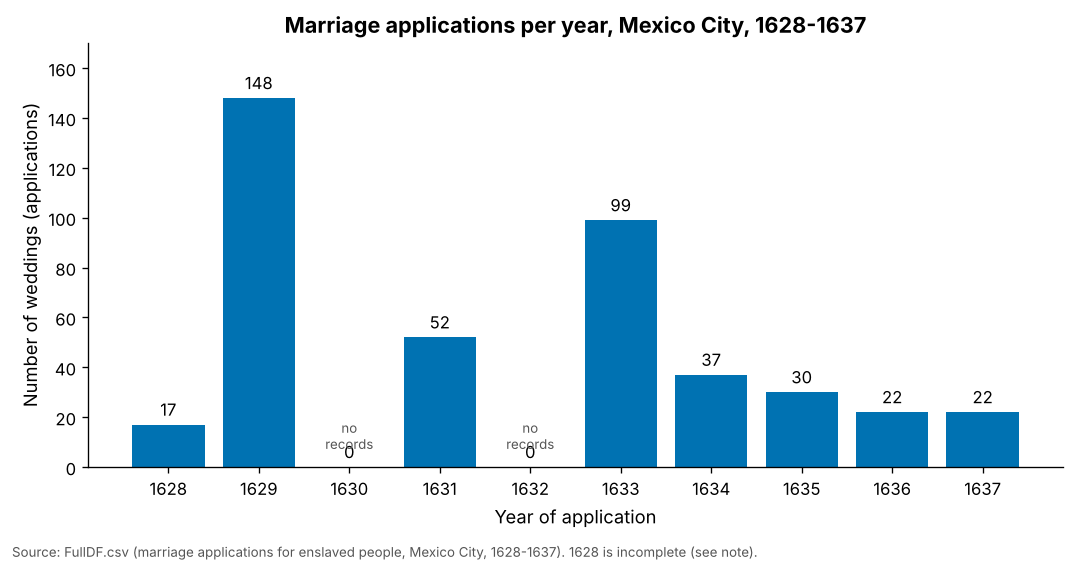

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.6))
bars = ax.bar(per_year.index.astype(str), per_year.values, color=PALETTE[0])
for x, v in zip(per_year.index.astype(str), per_year.values):
    ax.text(x, v + 2, str(v), ha="center", va="bottom", fontsize=10)

# Years with no surviving applications are real zeros in this dataset -> mark them
for yr in per_year.index[per_year.values == 0]:
    ax.text(str(yr), 6, "no\nrecords", ha="center", va="bottom", fontsize=8, color="#555555")

ax.set_title("Marriage applications per year, Mexico City, 1628-1637")
ax.set_xlabel("Year of application")
ax.set_ylabel("Number of weddings (applications)")
ax.set_ylim(0, per_year.max() * 1.15)
fig.text(0.01, -0.02, SOURCE_NOTE + ". 1628 is incomplete (see note).", fontsize=8, color="#555555")
plt.tight_layout()
plt.show()

**Reading this chart.** This is the number of applications that *survive in this dataset*, not the number of marriages that actually happened. Two cautions matter here:
- **1630 and 1632 show zero** because no applications from those years are in the data, not because there were no weddings.
- **1628 is incomplete.** The reading notes that as many as ~200 more applications from 1628 could not be collected because the archive withdrew most of that series from public access; only 17 were collected before that happened.

In [6]:
# Compare with the counts in the reading's Figure 5
reading_fig5 = {1628: 17, 1629: 149, 1630: 0, 1631: 52, 1632: 0,
                1633: 99, 1634: 37, 1635: 30, 1636: 22, 1637: 22}
cmp = pd.DataFrame({"this notebook (by wedding)": per_year,
                    "reading, Figure 5": pd.Series(reading_fig5)})
cmp["difference"] = cmp["this notebook (by wedding)"] - cmp["reading, Figure 5"]
print(cmp.to_string())

# Why is 1629 off by one?
multi = weddings[weddings["Citations"] > 1]
print("\nWeddings that cite two archival records:")
print(multi.to_string(index=False))

      this notebook (by wedding)  reading, Figure 5  difference
1628                          17                 17           0
1629                         148                149          -1
1630                           0                  0           0
1631                          52                 52           0
1632                           0                  0           0
1633                          99                 99           0
1634                          37                 37           0
1635                          30                 30           0
1636                          22                 22           0
1637                          22                 22           0

Weddings that cite two archival records:
WeddingID       Date  Citations  Year
    W0101 1629-08-23          2  1629


**Why 1629 differs by one.** Wedding W0101 appears under two archival citations (`010_150` and `088_003`). Counting by *citation* (as Figure 5 appears to) gives 149 for 1629 and 428 in total, while counting by *wedding* gives 148 and 427. Every other year matches. I count by wedding because the assignment asks for marriages.

## 3. Racial classification of the participants

### 3a. The raw labels
The `Race` column is the label the record gave each person. It is not a single clean category: it mixes terms like *Negro*, *Mulato*, and *Indio* with names of African "nations" or places of origin (for example *Angola*, *Congo*, *Bran*). There are 40 different spellings and abbreviations.

In [7]:
raw_counts = df["Race"].value_counts()
print(len(raw_counts), "distinct labels in", len(df), "rows")
raw_counts.to_frame("rows").T.T

40 distinct labels in 1811 rows


,rows
Race,
Angola,1031
Congo,214
Negro,116
Mulato,102
Bran,64
TNova,56
Esp,28
Ind,24
Mz,24


### 3b. Grouping the labels (my choices; please check them)
To make charts readable, I grouped the 40 labels into 9 broader categories. **This grouping is an interpretive choice, not something in the data**, and it is easy to change: edit the lists in the next cell and re-run everything below.

- **African nation named**: labels that name an African origin or port (Angola, Congo, Bran, Biafra, and so on). In the records, the standard practice was to write "Black" plus a place of origin.
- **Negro / Moreno (no nation)**: labelled Black without naming an origin.
- **Mulato**, **Indigenous (Indio)**, **Spanish (Español)**, **Asian (Chino)**, **Other casta (Morisco)**.
- **Unclear (Mz)**: the abbreviation `Mz` isn't obvious. It might mean *Mestizo* or an African origin, and I did not guess. **Please check your course codebook.**
- **Unknown**: `Unk`, `Unknown`, `?`.

Other judgment calls to verify: `TNova`/`TierraNova`/`Tierraguizama` were grouped with African nations, and the single label `Bañol` (one row) was too (it might be a variant of `Banon`).

In [8]:
GROUPS = {
    "African nation named": ["Angola", "Angolla", "Congo", "Bran", "Biolo (Bran)", "Biafra", "Biafara",
                             "Mozam", "Anchico", "Banon", "Bañol", "Jolofo", "Mandinga", "SanTome",
                             "Nalu", "Banguela", "Xoxa", "Carabali", "Zape", "CaboVerde", "Malemba",
                             "Bengalo", "TNova", "TierraNova", "Tierraguizama"],
    "Negro / Moreno (no nation)": ["Negro", "N", "Moreno"],
    "Mulato": ["Mulato"],
    "Indigenous (Indio)": ["Indio", "Ind", "India"],
    "Spanish (Espanol)": ["Esp", "Español"],
    "Asian (Chino)": ["Chino"],
    "Other casta (Morisco)": ["Morisco"],
    "Unclear (Mz)": ["Mz"],
    "Unknown": ["Unk", "Unknown", "?"],
}
GROUP_ORDER = list(GROUPS)
COLORS = dict(zip(GROUP_ORDER, PALETTE))

label_to_group = {lab: grp for grp, labs in GROUPS.items() for lab in labs}

# Safety check: every label in the data must be assigned to a group
unmapped = sorted(set(df["Race"]) - set(label_to_group))
assert not unmapped, f"Unmapped labels: {unmapped}"

df["RaceGroup"] = df["Race"].map(label_to_group)
df["RoleGroup"] = np.where(df["Role"] == "B", "Bride",
                    np.where(df["Role"] == "G", "Groom", "Witness"))
print("All", df["Race"].nunique(), "labels mapped to", df["RaceGroup"].nunique(), "groups")
df["RaceGroup"].value_counts().reindex(GROUP_ORDER).to_frame("rows")

All 40 labels mapped to 9 groups


,rows
RaceGroup,
African nation named,1479
Negro / Moreno (no nation),118
Mulato,102
Indigenous (Indio),28
Spanish (Espanol),30
Asian (Chino),14
Other casta (Morisco),1
Unclear (Mz),24
Unknown,15


### 3c. Rows vs. people
Since the same person can appear in many weddings (often as a witness), there are two ways to count: **rows** (appearances) and **unique people**. Which one a chart uses is stated in its title. For counts of *people*, a person's label is the one written most often for them (ties go to the first appearance). The check below shows how many people were labelled differently in different weddings.

In [9]:
def modal_label(s):
    return Counter(s).most_common(1)[0][0]      # ties -> first seen

n_labels = df.groupby("ID")["Race"].nunique()
print("People with more than one distinct Race label across weddings:",
      (n_labels > 1).sum(), "of", len(n_labels))

people = (df.sort_values("Date")
            .groupby("ID")
            .agg(Race=("Race", modal_label),
                 Status=("Status", modal_label),
                 Appearances=("WeddingID", "size"))
            .reset_index())
people["RaceGroup"] = people["Race"].map(label_to_group)
print("Unique people:", len(people))
people["RaceGroup"].value_counts().reindex(GROUP_ORDER).to_frame("people")

People with more than one distinct Race label across weddings: 18 of 1554
Unique people: 1554


,people
RaceGroup,
African nation named,1248
Negro / Moreno (no nation),96
Mulato,100
Indigenous (Indio),27
Spanish (Espanol),30
Asian (Chino),14
Other casta (Morisco),1
Unclear (Mz),24
Unknown,14


### Visualization A: bar chart of the raw labels (unique people)

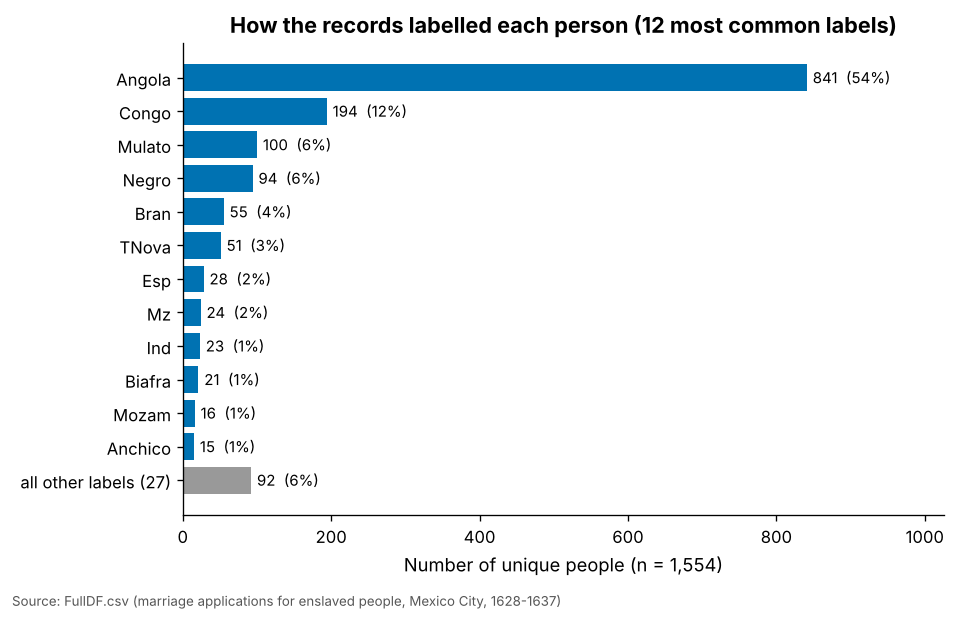

In [10]:
top = people["Race"].value_counts()
n_show = 12
shown = top.head(n_show)
other = top.iloc[n_show:].sum()
vals = pd.concat([shown, pd.Series({f"all other labels ({len(top)-n_show})": other})])

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(vals))[::-1]
ax.barh(y, vals.values, color=[PALETTE[0]]*n_show + [PALETTE[7]])
ax.set_yticks(y); ax.set_yticklabels(vals.index)
for yi, v in zip(y, vals.values):
    ax.text(v + 8, yi, f"{v:,}  ({v/len(people):.0%})", va="center", fontsize=9)
ax.set_xlim(0, vals.max() * 1.22)
ax.set_title("How the records labelled each person (12 most common labels)")
ax.set_xlabel(f"Number of unique people (n = {len(people):,})")
fig.text(0.01, -0.02, SOURCE_NOTE, fontsize=8, color="#555555")
plt.tight_layout(); plt.show()

**What this shows.** One label (`Angola`) accounts for most people, and a long tail of other labels follows. Because many labels name a place of origin and not a "race" in the modern sense, this chart is closer to a count of *how the record-keepers described origin* than a count of racial groups.

### Visualization B: pie (donut) chart of the grouped categories (unique people)

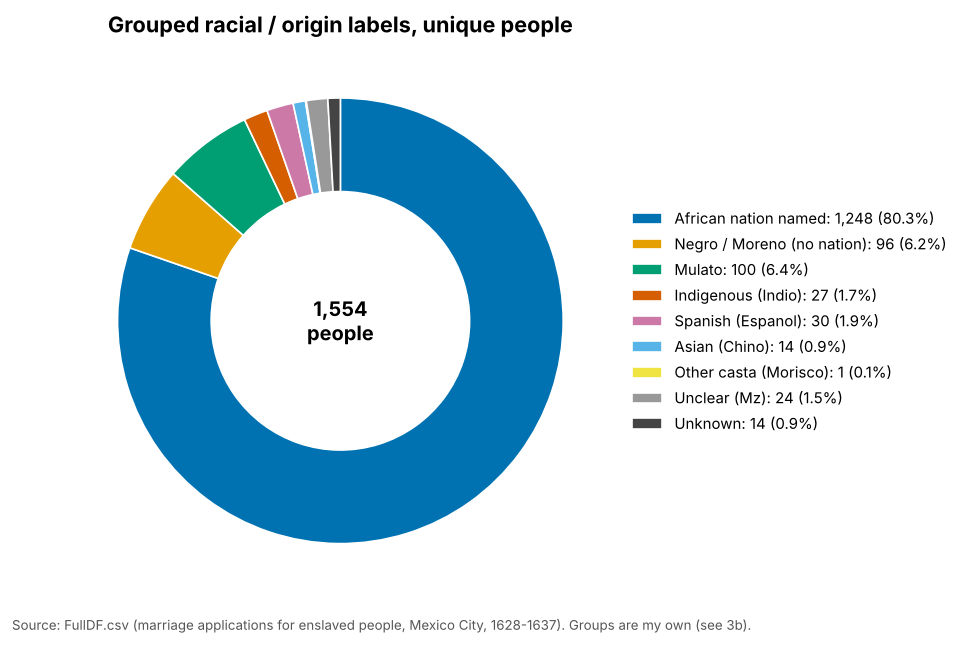

In [11]:
g = people["RaceGroup"].value_counts().reindex(GROUP_ORDER).dropna()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
wedges, _ = ax.pie(g.values, colors=[COLORS[k] for k in g.index], startangle=90,
                   counterclock=False, wedgeprops=dict(width=0.42, edgecolor="white"))
ax.legend(wedges, [f"{k}: {v:,} ({v/g.sum():.1%})" for k, v in g.items()],
          loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=9)
ax.text(0, 0, f"{g.sum():,}\npeople", ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_title("Grouped racial / origin labels, unique people")
fig.text(0.01, -0.02, SOURCE_NOTE + ". Groups are my own (see 3b).", fontsize=8, color="#555555")
plt.tight_layout(); plt.show()

**Note on this chart type.** A pie shows each group's share of the whole, but small slices are hard to compare by eye, which is why the exact counts and percentages are in the legend. The bar chart above and the stacked bars below are easier for comparing sizes.

### Visualization C: 100% stacked bar, label group by role in the wedding (rows)

/tmp/ipykernel_362/1412250257.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_yticklabels([f"{r}\n(n = {ct.loc[r].sum():,})" for r in pct.index])


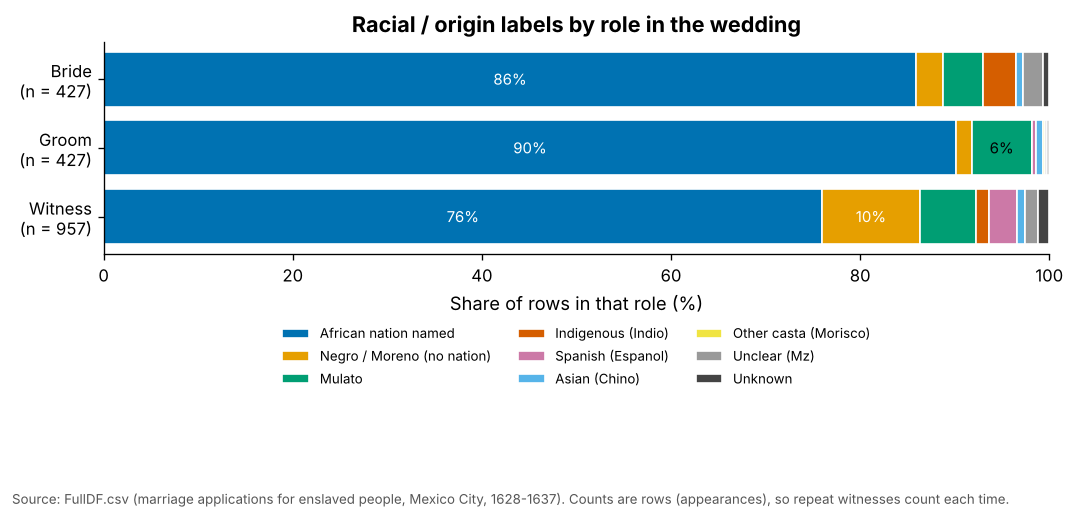

RaceGroup,African nation named,Negro / Moreno (no nation),Mulato,Indigenous (Indio),Spanish (Espanol),Asian (Chino),Other casta (Morisco),Unclear (Mz),Unknown
RoleGroup,,,,,,,,,
Bride,367,12,18,15,0,3,0,9,3
Groom,385,7,27,0,2,3,1,1,1
Witness,727,99,57,13,28,8,0,14,11


In [12]:
ct = pd.crosstab(df["RoleGroup"], df["RaceGroup"]).reindex(columns=GROUP_ORDER, fill_value=0)
ct = ct.loc[["Bride", "Groom", "Witness"]]
pct = ct.div(ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(pct))
for k in GROUP_ORDER:
    ax.barh(pct.index, pct[k], left=left, color=COLORS[k], label=k, edgecolor="white")
    for i, (p, l) in enumerate(zip(pct[k], left)):
        if p >= 6:
            ax.text(l + p/2, i, f"{p:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if k not in ("Mulato",) else "black")
    left += pct[k].values
ax.set_yticklabels([f"{r}\n(n = {ct.loc[r].sum():,})" for r in pct.index])
ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("Share of rows in that role (%)")
ax.set_title("Racial / origin labels by role in the wedding")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, frameon=False, fontsize=8)
fig.text(0.01, -0.12, SOURCE_NOTE + ". Counts are rows (appearances), so repeat witnesses count each time.",
         fontsize=8, color="#555555")
plt.tight_layout(); plt.show()
ct

### Visualization D: bubble chart, label group by year (rows)

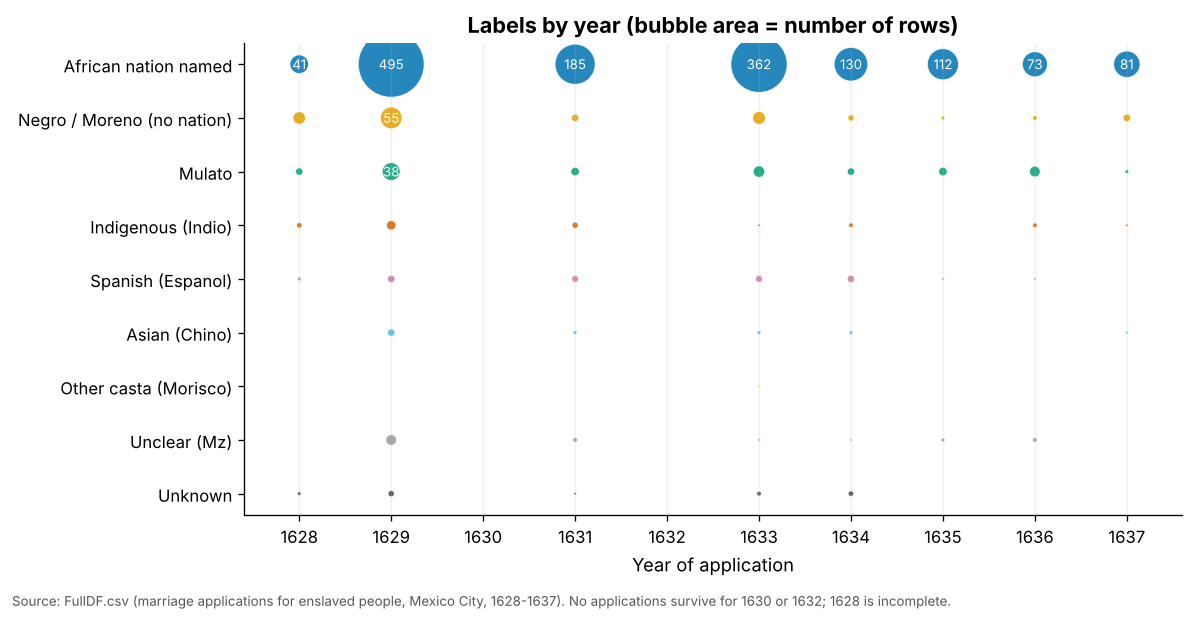

In [13]:
by_year = (df.assign(Year=df["Date"].dt.year)
             .groupby(["Year", "RaceGroup"]).size().rename("n").reset_index())
yrs = list(range(df["Date"].dt.year.min(), df["Date"].dt.year.max() + 1))
cats = [c for c in GROUP_ORDER if c in set(by_year["RaceGroup"])]
ypos = {c: i for i, c in enumerate(cats)}

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(by_year["Year"], by_year["RaceGroup"].map(ypos),
           s=by_year["n"] * 3.2, c=[COLORS[c] for c in by_year["RaceGroup"]],
           alpha=0.85, edgecolor="white", linewidth=0.8)
for _, r in by_year.iterrows():
    if r["n"] >= 30:
        ax.text(r["Year"], ypos[r["RaceGroup"]], str(r["n"]), ha="center", va="center",
                fontsize=8, color="white")
ax.set_yticks(range(len(cats))); ax.set_yticklabels(cats); ax.invert_yaxis()
ax.set_xticks(yrs); ax.set_xlim(yrs[0] - 0.6, yrs[-1] + 0.6)
ax.set_xlabel("Year of application"); ax.set_ylabel("")
ax.set_title("Labels by year (bubble area = number of rows)")
ax.grid(axis="x", alpha=0.2)
fig.text(0.01, -0.02, SOURCE_NOTE + ". No applications survive for 1630 or 1632; 1628 is incomplete.",
         fontsize=8, color="#555555")
plt.tight_layout(); plt.show()

**Reading this chart.** Bubble area is the number of rows with that label in that year, so a big bubble in a year with many applications (like 1629) mostly reflects how many applications survive, not a change in how people were labelled. Gaps in 1630 and 1632 are missing records.

### Visualization E: label group by legal status (unique people)

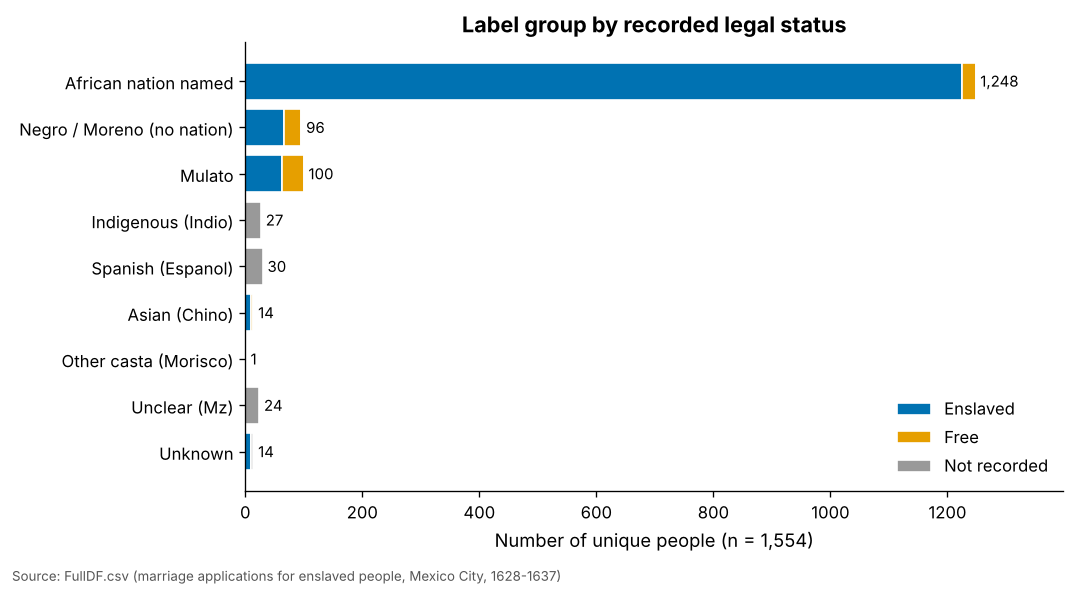

Status,Enslaved,Free,Not recorded
RaceGroup,,,
African nation named,1225,23,0
Negro / Moreno (no nation),67,29,0
Mulato,62,38,0
Indigenous (Indio),0,0,27
Spanish (Espanol),0,0,30
Asian (Chino),10,4,0
Other casta (Morisco),0,1,0
Unclear (Mz),0,0,24
Unknown,9,0,5


In [14]:
st = pd.crosstab(people["RaceGroup"], people["Status"]).reindex(GROUP_ORDER).dropna(how="all")
st = st[[c for c in ["Enslaved", "Free", "Not recorded"] if c in st.columns]]
status_colors = {"Enslaved": PALETTE[0], "Free": PALETTE[1], "Not recorded": PALETTE[7]}

fig, ax = plt.subplots(figsize=(9, 4.8))
bottom = np.zeros(len(st))
y = np.arange(len(st))[::-1]
for c in st.columns:
    ax.barh(y, st[c].values, left=bottom, color=status_colors[c], label=c, edgecolor="white")
    bottom += st[c].values
for yi, tot in zip(y, st.sum(axis=1)):
    ax.text(tot + 8, yi, f"{int(tot):,}", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(st.index)
ax.set_xlim(0, bottom.max() * 1.12)
ax.set_xlabel(f"Number of unique people (n = {len(people):,})")
ax.set_title("Label group by recorded legal status")
ax.legend(frameon=False, loc="lower right")
fig.text(0.01, -0.02, SOURCE_NOTE, fontsize=8, color="#555555")
plt.tight_layout(); plt.show()
st

## 4. Stretch goal: the edges file

**What an edges file is.** To analyze the weddings as a network, each person is a *node* and each relationship is an *edge*, a row with a `Source` ID and a `Target` ID.

**The rule I used** (based on `Role` and `For`). For each wedding:
1. **Bride and groom:** one edge, bride (`Source`) to groom (`Target`).
2. **Each witness** is connected to the person or people they speak for:
   - `For = Bride`: one edge, witness to bride.
   - `For = Groom`: one edge, witness to groom.
   - `For = Both`: two edges, witness to bride and witness to groom.

Connections *between* witnesses are not included, because the records only state each witness's link to the bride or groom. Since people reappear across weddings, the same ID in several weddings is what connects them into larger networks.

In [15]:
def build_edges(data):
    rows = []
    for wid, g in data.groupby("WeddingID", sort=False):
        brides = g.loc[g["Role"] == "B", "ID"].tolist()
        grooms = g.loc[g["Role"] == "G", "ID"].tolist()

        # 1) bride <-> groom
        for b in brides:
            for gr in grooms:
                rows.append((b, gr, wid, "bride-groom"))

        # 2) each witness -> the party/parties they speak for
        for _, w in g[g["Role"].str.startswith("W")].iterrows():
            if w["For"] in ("Bride", "Both"):
                for b in brides:
                    rows.append((w["ID"], b, wid, "witness-bride"))
            if w["For"] in ("Groom", "Both"):
                for gr in grooms:
                    rows.append((w["ID"], gr, wid, "witness-groom"))
    return pd.DataFrame(rows, columns=["Source", "Target", "WeddingID", "Type"])

edges_detailed = build_edges(df)
edges = edges_detailed[["Source", "Target"]]          # exactly two columns, as requested

print("Edges built:", len(edges), "(reading reports 2,140)")
print(edges_detailed["Type"].value_counts().to_string())
edges.head(10)

Edges built: 2140 (reading reports 2,140)
Type
witness-bride    860
witness-groom    853
bride-groom      427


,Source,Target
0,P1534,P1533
1,P1523,P1534
2,P1525,P1533
3,P1536,P1534
4,P1535,P1533
5,P1538,P1537
6,P1539,P1538
7,P1539,P1537
8,P1532,P1538
9,P1532,P1537


In [16]:
# Checks: every edge endpoint is a real person ID; no self-loops; no duplicate pairs
all_ids = set(df["ID"])
assert edges["Source"].isin(all_ids).all() and edges["Target"].isin(all_ids).all()
assert (edges["Source"] != edges["Target"]).all()
pairs = {tuple(sorted(t)) for t in zip(edges["Source"], edges["Target"])}
print("Unique undirected pairs:", len(pairs), "| rows:", len(edges))

# Witnesses with no 'For' value would be silently skipped, so confirm there are none
w = df[df["Role"].str.startswith("W")]
print("Witness rows with a missing/unknown 'For':", (~w["For"].isin(["Bride", "Groom", "Both"])).sum())

# Save
edges.to_csv("edges.csv", index=False)                      # Source, Target
edges_detailed.to_csv("edges_detailed.csv", index=False)    # + WeddingID and Type (for reference)
print("Saved edges.csv and edges_detailed.csv")

Unique undirected pairs: 2140 | rows: 2140
Witness rows with a missing/unknown 'For': 0
Saved edges.csv and edges_detailed.csv


In [17]:
# Quick sanity check: how many separate connected groups do these edges form?
parent = {i: i for i in all_ids}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for s, t in zip(edges["Source"], edges["Target"]):
    parent[find(s)] = find(t)

sizes = Counter(find(i) for i in all_ids)
size_list = sorted(sizes.values(), reverse=True)
print("Connected groups of people:", len(sizes))
print("Largest groups (number of people):", size_list[:6])
print("Groups that are a single wedding party (<= 6 people):", sum(1 for s in size_list if s <= 6))

Connected groups of people: 194
Largest groups (number of people): [410, 79, 33, 21, 19, 19]
Groups that are a single wedding party (<= 6 people): 160


**About this check.** It only confirms the edges file behaves like a network (one very large connected group, many small ones). The reading reports slightly different counts in different places for the largest group (410 in the text, 385 in Table 1), so I do not treat any one of its figures as an exact target. The edge total (2,140) does match exactly.

**To use the file elsewhere:** `edges.csv` can be loaded directly into Gephi or Cytoscape, or into Python's `networkx` with `nx.from_pandas_edgelist(edges, "Source", "Target")`.

## 5. Limits of this analysis

- **Survival bias.** Everything here describes applications that survive in the dataset, which is under half of all marriages for the period according to the reading.
- **The grouping is mine.** Collapsing 40 labels into 9 categories makes charts readable but also decides what counts as "the same." A different grouping would change the charts.
- **Labels are what record-keepers wrote.** They are not self-descriptions, and the same person is sometimes labelled differently across weddings.
- **Edges treat different relationships alike.** A marriage and a witness connection are not the same kind of tie, but both are one row here.

## 6. My reflection

**Reflection question 1 (Houston, on corpora and modeling):** Houston argues a corpus is not neutral — it's "an artificial object created by a researcher," and every choice about what to include has to be justified. Section 3b of this notebook collapsed 40 race/origin labels into 9 groups, and explicitly flagged several of those calls as uncertain (`Mz`, `Bañol`, `TNova`/`TierraNova`). In your own words, how does that grouping decision illustrate Houston's point? What would you want to check before trusting any chart built on top of it?

> Your answer here:
>
>

**Reflection question 2 (Houston, three kinds of modeling):** Houston distinguishes descriptive, generative, and predictive modeling. Which of those three best describes every visualization in this notebook, and why wasn't a different kind — like topic modeling or a trained classifier — used or needed for this particular dataset and question?

> Your answer here:
>
>

**Reflection question 3 (Underwood, AI as a cultural technology):** Underwood frames AI's real upside as the ability to "map and edit culture" — finding patterns invisible at the scale of reading one document at a time. The edges file here revealed 194 separate connected social groups, including one of 410 people, built entirely out of witness relationships across hundreds of individually unremarkable weddings. How does that connect to Underwood's idea of AI as something that extends collective human power, rather than replacing human judgment?

> Your answer here:
>
>

**Reflection question 4 (Cohen, the line to resist):** Cohen argues AI should handle "the monotonous part" of historical work (transcription, search, cleanup) so historians can spend their time on interpretation, and that using AI to produce the interpretation itself is "the line to resist." This notebook's disclosure says the AI wrote all the code and checked the numbers, but was deliberately not asked to explain what the patterns mean. Where did you actually draw that line while working through this assignment? Was there a moment you were tempted to just accept an AI-generated explanation instead of working one out yourself?

> Your answer here:
>
>

**Reflection question 5 (your own process):** What in the charts above surprised you, or raised a question you didn't expect going in? And which of the grouping choices in section 3b would you personally reconsider, and why?

> Your answer here:
>
>

---
**Files produced:** `edges.csv` (Source, Target), `edges_detailed.csv` (adds WeddingID and Type), and this notebook (`.ipynb`) with an `.html` copy.